<a href="https://colab.research.google.com/github/Ruy1024/Trabalho-Pesquisa-Acad-mica/blob/main/Trabalho_Pesquisa_Acad%C3%AAmica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Geometria sem tamanho: impacto da remoção dos atributos dimensionais na classificação de feijões secos

**Conjunto de dados**: Dry Bean Dataset, UCI Machine Learning Repository, id 602, DOI 10.24432/C50S4B, licença CC BY 4.0.

**Pergunta de pesquisa:** os atributos adimensionais de formato, sozinhos, mantêm o desempenho de classificação das 7 variedades obtido com o conjunto completo de 16 atributos?

**Reprodutibilidade:** semente global `SEED = 42`; validação cruzada estratificada 5-fold repetida 10 vezes (50 folds). O tempo de execução é de cerca de 15 a 20 minutos em 2 núcleos de CPU.

In [ ]:
import time, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy
from scipy import stats
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, confusion_matrix

SEED = 42

## 1. Carga dos dados

O notebook baixa o conjunto de dados pelo pacote "ucimlrepo".

In [ ]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=602)  # o ID está na página do conjunto
X = dataset.data.features
y = dataset.data.targets
print(dataset.metadata)
print(dataset.variables)

{'uci_id': 602, 'name': 'Dry Bean', 'repository_url': 'https://archive.ics.uci.edu/dataset/602/dry+bean+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/602/data.csv', 'abstract': 'Images of 13,611 grains of 7 different registered dry beans were taken with a high-resolution camera. A total of 16 features; 12 dimensions and 4 shape forms, were obtained from the grains.', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 13611, 'num_features': 16, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Thu Mar 28 2024', 'dataset_doi': '10.24432/C50S4B', 'creators': [], 'intro_paper': {'ID': 244, 'type': 'NATIVE', 'title': 'Multiclass classification of dry beans using computer vision and machine learning techniques', 'authors': 'M. Koklu, Ilker Ali Özkan', 'venue': 'Co

## 2. Análise Exploratória


In [ ]:
print('Valores ausentes:', raw.isna().sum().sum())
print('Linhas duplicadas:', raw.duplicated().sum())
dist = raw.Class.value_counts()
print(pd.DataFrame({'n': dist, '%': (100 * dist / len(raw)).round(1)}))
print('Razão maior/menor classe:', round(dist.max() / dist.min(), 2))

Valores ausentes: 0
Linhas duplicadas: 68
             n     %
Class               
DERMASON  3546  26.1
SIRA      2636  19.4
SEKER     2027  14.9
HOROZ     1928  14.2
CALI      1630  12.0
BARBUNYA  1322   9.7
BOMBAY     522   3.8
Razão maior/menor classe: 6.79


In [ ]:
print('Classe das linhas duplicadas:', raw[raw.duplicated()].Class.value_counts().to_dict())
d = raw.drop_duplicates().reset_index(drop=True)
print('Instâncias após remover duplicatas:', len(d))
dist2 = d.Class.value_counts()
print(pd.DataFrame({'n': dist2, '%': (100 * dist2 / len(d)).round(1)}))
print('Razão maior/menor classe:', round(dist2.max() / dist2.min(), 2))

Classe das linhas duplicadas: {'HOROZ': 68}
Instâncias após remover duplicatas: 13543
             n     %
Class               
DERMASON  3546  26.2
SIRA      2636  19.5
SEKER     2027  15.0
HOROZ     1860  13.7
CALI      1630  12.0
BARBUNYA  1322   9.8
BOMBAY     522   3.9
Razão maior/menor classe: 6.79


In [ ]:
corr = d.drop(columns='Class').corr()
alta = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) >= 0.95]
pd.DataFrame(alta, columns=['atributo A', 'atributo B', 'r de Pearson'])

,atributo A,atributo B,r de Pearson
0,Area,Perimeter,0.967
1,Area,MinorAxisLength,0.952
2,Area,ConvexArea,1.000
3,Area,EquivDiameter,0.985
4,Perimeter,MajorAxisLength,0.978
5,Perimeter,ConvexArea,0.968
6,Perimeter,EquivDiameter,0.991
7,MajorAxisLength,EquivDiameter,0.962
8,MinorAxisLength,ConvexArea,0.952
9,AspectRatio,Compactness,-0.988


## 3. Classificação dos atributos por dimensão física

A documentação da UCI não traz as fórmulas de ShapeFactor1 a ShapeFactor4. Para saber quais atributos dependem da escala da imagem, cada fator de forma é ajustado como potência de A (área), L (eixo maior) e l (eixo menor): log SF = a·log A + b·log L + c·log l + k. Um atributo é adimensional quando 2a + b + c = 0, porque assim não muda se a imagem for ampliada ou reduzida.

In [ ]:
X = np.column_stack([np.log(d.Area), np.log(d.MajorAxisLength), np.log(d.MinorAxisLength), np.ones(len(d))])
linhas = []
for c in ['ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'AspectRatio', 'Compactness']:
    b, *_ = np.linalg.lstsq(X, np.log(d[c]), rcond=None)
    resid = np.std(np.log(d[c]) - X @ b)
    grau = 2 * b[0] + b[1] + b[2]   # expoente total de comprimento
    linhas.append([c, *np.round(b[:3], 3), round(grau, 3), f'{resid:.1e}'])
pd.DataFrame(linhas, columns=['atributo', 'exp. A', 'exp. L', 'exp. l', 'dimensão (comprimento^)', 'resíduo'])

,atributo,exp. A,exp. L,exp. l,dimensão (comprimento^),resíduo
0,ShapeFactor1,-1.0,1.0,0.0,-1.0,4.7e-08
1,ShapeFactor2,1.0,-3.0,-0.0,-1.0,2.0e-07
2,ShapeFactor3,1.0,-2.0,0.0,0.0,5.0e-10
3,ShapeFactor4,1.0,-1.0,-1.0,-0.0,3.4e-10
4,AspectRatio,0.0,1.0,-1.0,-0.0,2.6e-10
5,Compactness,0.5,-1.0,0.0,-0.0,3.8e-10


Resultado: SF1 = L/A e SF2 = A/L³, ambos com dimensão de comprimento⁻¹. Eles dependem da escala, apesar do nome "fator de forma". SF3 = A/(πL²/4) e SF4 = A/(πLl/4) são adimensionais. Os grupos usados no experimento ficam assim:

In [ ]:
LEN  = ['Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'EquivDiameter']   # escalam com k
AREA = ['Area', 'ConvexArea']                                               # escalam com k^2
INV  = ['ShapeFactor1', 'ShapeFactor2']                                     # escalam com 1/k
SHAPE = ['AspectRatio', 'Eccentricity', 'Extent', 'Solidity', 'Roundness',
         'Compactness', 'ShapeFactor3', 'ShapeFactor4']                     # adimensionais
COND = {
    'C1_todos16': LEN + AREA + INV + SHAPE,
    'C2_forma8': SHAPE,
    'C3_forma10_ingenuo': SHAPE + INV,
    'C4_tamanho6': LEN + AREA,
}
for k, v in COND.items():
    print(f'{k:20s} {len(v):2d} atributos')

C1_todos16           16 atributos
C2_forma8             8 atributos
C3_forma10_ingenuo   10 atributos
C4_tamanho6           6 atributos


## 4. Experimento

* **Variável independente:** conjunto de atributos (C1 a C4).
* **Variáveis dependentes:** F1-macro (principal), acurácia e acurácia balanceada.
* **Modelos:** Regressão Logística, kNN (k = 5), SVM com kernel RBF e Random Forest (200 árvores), todos com hiperparâmetros padrão. A padronização (z-score) é ajustada só no treino de cada fold, dentro do pipeline.
* **Validação:** `RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)`. Os mesmos 50 folds valem para todas as condições, o que permite comparações pareadas.
* **Análise complementar de escala:** cada modelo treinado é avaliado também no fold de teste com os atributos transformados como se a imagem tivesse escala k ∈ {0,8; 0,9; 1,1; 1,2}.

In [ ]:
le = LabelEncoder(); y = le.fit_transform(d.Class)
MODELS = {
    'LR':  lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    'kNN': lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'SVM': lambda: make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, gamma='scale')),
    'RF':  lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}
SCALES = [0.8, 0.9, 1.1, 1.2]

def reescala(Xdf, k):
    Xdf = Xdf.copy()
    for c in Xdf.columns:
        if c in LEN:    Xdf[c] *= k
        elif c in AREA: Xdf[c] *= k ** 2
        elif c in INV:  Xdf[c] /= k
    return Xdf

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
rows, rob, cms = [], [], {}
t0 = time.time()
for fold, (tr, te) in enumerate(cv.split(d, y)):
    for cn, cols in COND.items():
        Xtr, Xte = d.loc[tr, cols], d.loc[te, cols]
        for mn, mk in MODELS.items():
            m = mk().fit(Xtr, y[tr]); p = m.predict(Xte)
            rows.append(dict(fold=fold, cond=cn, model=mn,
                             acc=accuracy_score(y[te], p), bacc=balanced_accuracy_score(y[te], p),
                             f1m=f1_score(y[te], p, average='macro'),
                             **{f'f1_{c}': v for c, v in zip(le.classes_, f1_score(y[te], p, average=None))}))
            cms[(cn, mn)] = cms.get((cn, mn), 0) + confusion_matrix(y[te], p)
            if cn != 'C4_tamanho6':
                for k in SCALES:
                    pk = m.predict(reescala(Xte, k))
                    rob.append(dict(fold=fold, cond=cn, model=mn, k=k, f1m=f1_score(y[te], pk, average='macro')))
    if fold % 5 == 4:
        print(f'repetição {fold // 5 + 1}/10 concluída ({time.time() - t0:.0f} s)')

r = pd.DataFrame(rows); rb = pd.DataFrame(rob)
r.to_csv('resultados_folds.csv', index=False); rb.to_csv('resultados_escala.csv', index=False)

repetição 1/10 concluída (159 s)
repetição 2/10 concluída (313 s)
repetição 3/10 concluída (467 s)
repetição 4/10 concluída (620 s)
repetição 5/10 concluída (773 s)
repetição 6/10 concluída (928 s)
repetição 7/10 concluída (1081 s)
repetição 8/10 concluída (1234 s)
repetição 9/10 concluída (1388 s)
repetição 10/10 concluída (1542 s)


## 5. Resultados

### Tabela 2: média e desvio-padrão nos 50 folds (%)

In [ ]:
ORD_C = ['C1_todos16', 'C2_forma8', 'C3_forma10_ingenuo', 'C4_tamanho6']
ORD_M = ['LR', 'kNN', 'SVM', 'RF']
g = r.groupby(['model', 'cond'])[['acc', 'bacc', 'f1m']].agg(['mean', 'std']) * 100
tab = pd.DataFrame({m: [f"{g.loc[(m, c), ('f1m', 'mean')]:.2f} ± {g.loc[(m, c), ('f1m', 'std')]:.2f}" for c in ORD_C] for m in ORD_M}, index=ORD_C)
print('F1-macro (%)');
display(tab)
print('Acurácia e acurácia balanceada (%)');
display(g.loc[ORD_M].round(2))

F1-macro (%)


,LR,kNN,SVM,RF
C1_todos16,93.58 ± 0.48,93.48 ± 0.45,94.05 ± 0.44,93.52 ± 0.45
C2_forma8,71.74 ± 0.88,72.02 ± 0.82,75.11 ± 0.78,73.62 ± 0.96
C3_forma10_ingenuo,93.59 ± 0.45,93.21 ± 0.39,94.08 ± 0.43,93.78 ± 0.40
C4_tamanho6,91.87 ± 0.50,91.84 ± 0.53,91.88 ± 0.50,91.82 ± 0.46


Acurácia e acurácia balanceada (%)


acc         bacc          f1m      
                           mean   std   mean   std   mean   std
model cond                                                     
LR    C1_todos16          92.39  0.52  93.48  0.48  93.58  0.48
      C2_forma8           75.90  0.61  70.74  0.79  71.74  0.88
      C3_forma10_ingenuo  92.39  0.50  93.52  0.45  93.59  0.45
      C4_tamanho6         90.64  0.58  91.67  0.52  91.87  0.50
kNN   C1_todos16          92.21  0.50  93.32  0.46  93.48  0.45
      C2_forma8           75.02  0.71  71.58  0.81  72.02  0.82
      C3_forma10_ingenuo  91.93  0.45  93.08  0.40  93.21  0.39
      C4_tamanho6         90.67  0.58  91.57  0.54  91.84  0.53
SVM   C1_todos16          92.88  0.50  93.88  0.44  94.05  0.44
      C2_forma8           78.74  0.62  74.03  0.69  75.11  0.78
      C3_forma10_ingenuo  92.93  0.49  93.94  0.43  94.08  0.43
      C4_tamanho6         90.77  0.57  91.53  0.52  91.88  0.50
RF    C1_todos16          92.40  0.49  93.37  0.44  93.52  0.45
      C2_forma8           77.13  0.72  72.76  0.81  73.62  0.96
      C3_forma10_ingenuo  92.59  0.48  93.62  0.41  93.78  0.40
      C4_tamanho6         90.76  0.50  91.64  0.46  91.82  0.46

### Tabela 3: comparações pareadas (F1-macro, pontos percentuais)

Teste t de reamostragem corrigido de Nadeau e Bengio (2003): a variância das diferenças é multiplicada por (1/J + n_teste/n_treino), com J = 50 e n_teste/n_treino = 1/4, e df = J − 1. O teste de Wilcoxon pareado é dado como verificação não paramétrica. Com 50 pares e todas as diferenças com o mesmo sinal, o menor p possível do Wilcoxon é 1,78·10⁻¹⁵.

In [ ]:
def t_corrigido(a, b, razao=0.25):
    dd = a - b; J = len(dd)
    se = np.sqrt((1 / J + razao) * dd.var(ddof=1))
    t = dd.mean() / se
    meia = stats.t.ppf(0.975, J - 1) * se
    return dd.mean(), dd.mean() - meia, dd.mean() + meia, t, 2 * stats.t.sf(abs(t), J - 1)

def vetor(m, c):
    return r[(r.model == m) & (r.cond == c)].sort_values('fold').f1m.values * 100

linhas = []
for A, B in [('C1_todos16', 'C2_forma8'), ('C3_forma10_ingenuo', 'C1_todos16'), ('C1_todos16', 'C4_tamanho6')]:
    for m in ORD_M:
        a, b = vetor(m, A), vetor(m, B)
        dif, lo, hi, t, p = t_corrigido(a, b)
        linhas.append([f'{A} − {B}', m, round(dif, 2), f'[{lo:.2f}; {hi:.2f}]', round(t, 2), f'{p:.1e}',
                       f'{stats.wilcoxon(a, b).pvalue:.1e}', int((a > b).sum())])
pd.DataFrame(linhas, columns=['comparação', 'modelo', 'diferença média', 'IC 95%', 't', 'p (t corrigido)', 'p (Wilcoxon)', 'folds A > B'])

,comparação,modelo,diferença média,IC 95%,t,p (t corrigido),p (Wilcoxon),folds A > B
0,C1_todos16 − C2_forma8,LR,21.84,[20.92; 22.75],47.71,9.8e-43,1.8e-15,50
1,C1_todos16 − C2_forma8,kNN,21.46,[20.60; 22.32],50.05,9.8e-44,1.8e-15,50
2,C1_todos16 − C2_forma8,SVM,18.93,[18.12; 19.74],46.97,2.1e-42,1.8e-15,50
3,C1_todos16 − C2_forma8,RF,19.90,[18.85; 20.95],38.08,4.6e-38,1.8e-15,50
4,C3_forma10_ingenuo − C1_todos16,LR,0.02,[-0.12; 0.15],0.27,7.9e-01,3.7e-01,29
5,C3_forma10_ingenuo − C1_todos16,kNN,-0.27,[-0.54; -0.01],-2.05,4.5e-02,8.2e-09,9
6,C3_forma10_ingenuo − C1_todos16,SVM,0.04,[-0.15; 0.22],0.40,6.9e-01,1.5e-01,30
7,C3_forma10_ingenuo − C1_todos16,RF,0.26,[0.03; 0.49],2.24,3.0e-02,2.8e-10,43
8,C1_todos16 − C4_tamanho6,LR,1.71,[1.37; 2.04],10.17,1.1e-13,1.8e-15,50
9,C1_todos16 − C4_tamanho6,kNN,1.65,[1.11; 2.18],6.19,1.2e-07,1.8e-15,50


### Figura complementar: F1-macro por conjunto de atributos

Não incluída no artigo; os mesmos valores estão na Tabela 2.

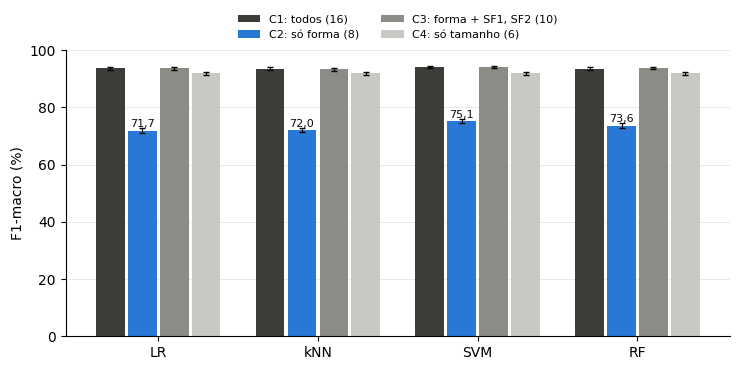

In [ ]:
CINZA, AZUL = '#8c8b86', '#2a78d6'
COR = {'C1_todos16': '#3d3c39', 'C2_forma8': AZUL, 'C3_forma10_ingenuo': '#8c8b86', 'C4_tamanho6': '#c9c8c2'}
ROT = {'C1_todos16': 'C1: todos (16)', 'C2_forma8': 'C2: só forma (8)', 'C3_forma10_ingenuo': 'C3: forma + SF1, SF2 (10)', 'C4_tamanho6': 'C4: só tamanho (6)'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

fig, ax = plt.subplots(figsize=(7.5, 3.8))
w = 0.2
for j, c in enumerate(ORD_C):
    mu = [g.loc[(m, c), ('f1m', 'mean')] for m in ORD_M]
    sd = [g.loc[(m, c), ('f1m', 'std')] for m in ORD_M]
    xs = np.arange(4) + (j - 1.5) * w
    ax.bar(xs, mu, w * 0.9, yerr=sd, color=COR[c], label=ROT[c], capsize=2, error_kw={'lw': 0.8})
    if c == 'C2_forma8':
        for x, v in zip(xs, mu):
            ax.text(x, v + 1.2, f'{v:.1f}'.replace('.', ','), ha='center', fontsize=8, color='#0b0b0b')
ax.set_xticks(range(4), ORD_M); ax.set_ylim(0, 100); ax.set_ylabel('F1-macro (%)')
ax.yaxis.grid(True, color='#e6e5e0', lw=0.6); ax.set_axisbelow(True)
ax.legend(ncol=2, fontsize=8, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(); fig.savefig('fig1_f1_condicoes.png', dpi=200); plt.show()

### Figura 1 do artigo e matrizes de confusão: F1 por classe (SVM)

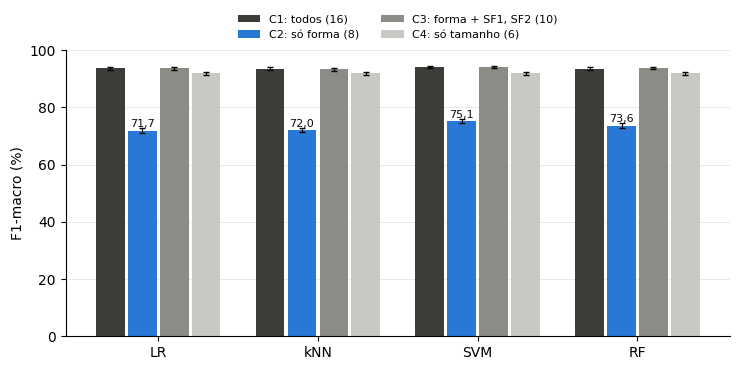

In [ ]:
CINZA, AZUL = '#8c8b86', '#2a78d6'
COR = {'C1_todos16': '#3d3c39', 'C2_forma8': AZUL, 'C3_forma10_ingenuo': '#8c8b86', 'C4_tamanho6': '#c9c8c2'}
ROT = {'C1_todos16': 'C1: todos (16)', 'C2_forma8': 'C2: só forma (8)', 'C3_forma10_ingenuo': 'C3: forma + SF1, SF2 (10)', 'C4_tamanho6': 'C4: só tamanho (6)'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

fig, ax = plt.subplots(figsize=(7.5, 3.8))
w = 0.2
for j, c in enumerate(ORD_C):
    mu = [g.loc[(m, c), ('f1m', 'mean')] for m in ORD_M]
    sd = [g.loc[(m, c), ('f1m', 'std')] for m in ORD_M]
    xs = np.arange(4) + (j - 1.5) * w
    ax.bar(xs, mu, w * 0.9, yerr=sd, color=COR[c], label=ROT[c], capsize=2, error_kw={'lw': 0.8})
    if c == 'C2_forma8':
        for x, v in zip(xs, mu):
            ax.text(x, v + 1.2, f'{v:.1f}'.replace('.', ','), ha='center', fontsize=8, color='#0b0b0b')
ax.set_xticks(range(4), ORD_M); ax.set_ylim(0, 100); ax.set_ylabel('F1-macro (%)')
ax.yaxis.grid(True, color='#e6e5e0', lw=0.6); ax.set_axisbelow(True)
ax.legend(ncol=2, fontsize=8, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(); fig.savefig('fig1_f1_condicoes.png', dpi=200); plt.show()

### Figura 1 do artigo e matrizes de confusão: F1 por classe (SVM)

f1_BARBUNYA  f1_BOMBAY  f1_CALI  f1_DERMASON  f1_HOROZ  \
model cond                                                                 
LR    C1_todos16         92.4      100.0     93.9         92.0      95.4   
      C2_forma8          84.4       30.4     70.4         76.8      90.9   
RF    C1_todos16         92.4       99.8     93.6         92.0      95.1   
      C2_forma8          84.6       36.6     72.3         76.6      91.3   
SVM   C1_todos16         93.2      100.0     94.5         92.1      95.8   
      C2_forma8          86.4       37.8     74.7         79.0      92.1   
kNN   C1_todos16         92.6      100.0     93.8         91.4      95.4   
      C2_forma8          83.4       36.3     70.6         74.4      91.1   

                  f1_SEKER  f1_SIRA  
model cond                           
LR    C1_todos16      94.8     86.7  
      C2_forma8       91.4     58.0  
RF    C1_todos16      94.8     86.9  
      C2_forma8       91.6     62.3  
SVM   C1_todos16      95.2     87.5  
      C2_forma8       92.3     63.5  
kNN   C1_todos16      94.7     86.4  
      C2_forma8       91.4     57.1

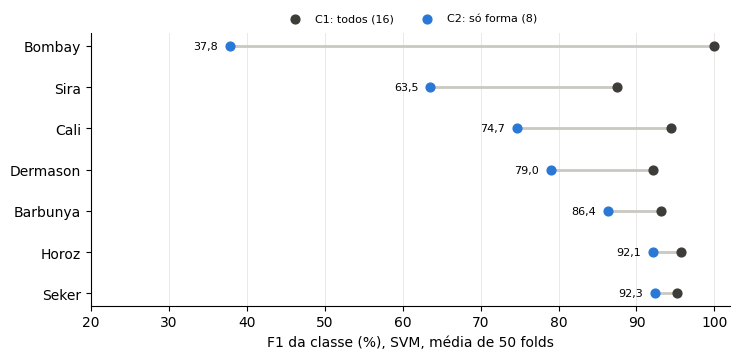

('C1_todos16', 'SVM') (média por repetição)


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
BARBUNYA,1202,0,76,0,5,10,29
BOMBAY,0,522,0,0,0,0,0
CALI,36,0,1553,0,25,3,13
DERMASON,0,0,0,3283,5,51,207
HOROZ,3,0,26,15,1775,0,41
SEKER,9,0,0,37,1,1924,56
SIRA,7,0,2,244,36,26,2321


('C2_forma8', 'SVM') (média por repetição)


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
BARBUNYA,1128,13,21,20,13,17,111
BOMBAY,18,138,201,8,9,12,135
CALI,12,25,1285,3,88,2,214
DERMASON,60,3,19,2882,5,72,506
HOROZ,5,0,117,8,1702,0,27
SEKER,30,1,0,149,1,1833,12
SIRA,36,27,169,682,18,8,1696


In [ ]:
fc = [f'f1_{c}' for c in le.classes_]
pc = r[r.cond.isin(['C1_todos16', 'C2_forma8'])].groupby(['model', 'cond'])[fc].mean() * 100
display(pc.round(1))

s1, s2 = pc.loc[('SVM', 'C1_todos16')], pc.loc[('SVM', 'C2_forma8')]
ordem = (s1 - s2).sort_values().index
fig, ax = plt.subplots(figsize=(7.5, 3.7))
for i, c in enumerate(ordem):
    ax.plot([s2[c], s1[c]], [i, i], color='#c9c8c2', lw=2, zorder=1)
    ax.scatter(s1[c], i, color='#3d3c39', s=40, zorder=2, label='C1: todos (16)' if i == 0 else None)
    ax.scatter(s2[c], i, color=AZUL, s=40, zorder=2, label='C2: só forma (8)' if i == 0 else None)
    ax.text(s2[c] - 1.5, i, f'{s2[c]:.1f}'.replace('.', ','), va='center', ha='right', fontsize=8)
ax.set_yticks(range(len(ordem)), [c.replace('f1_', '').capitalize() for c in ordem])
ax.set_xlim(20, 102); ax.set_xlabel('F1 da classe (%), SVM, média de 50 folds')
ax.xaxis.grid(True, color='#e6e5e0', lw=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, ncol=2, loc='lower center', bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(); fig.savefig('fig2_f1_por_classe.png', dpi=200); plt.show()

for key in [('C1_todos16', 'SVM'), ('C2_forma8', 'SVM')]:
    print(key, '(média por repetição)')
    display(pd.DataFrame((cms[key] / 10).round(0).astype(int), index=le.classes_, columns=le.classes_))

### Figura 2 do artigo: sensibilidade à escala da imagem

k                           0.8    0.9    1.0    1.1    1.2
model cond                                                 
LR    C1_todos16          38.38  76.22  93.58  79.82  52.11
      C2_forma8           71.74  71.74  71.74  71.74  71.74
      C3_forma10_ingenuo  40.10  76.44  93.59  80.50  53.08
RF    C1_todos16          34.40  74.09  93.52  79.63  50.75
      C2_forma8           73.62  73.62  73.62  73.62  73.62
      C3_forma10_ingenuo  37.44  75.11  93.78  80.36  55.45
SVM   C1_todos16          41.16  78.27  94.05  82.53  54.97
      C2_forma8           75.11  75.11  75.11  75.11  75.11
      C3_forma10_ingenuo  44.92  79.99  94.08  83.59  58.60
kNN   C1_todos16          43.57  79.06  93.48  81.72  54.90
      C2_forma8           72.02  72.02  72.02  72.02  72.02
      C3_forma10_ingenuo  52.16  81.13  93.21  83.94  61.27

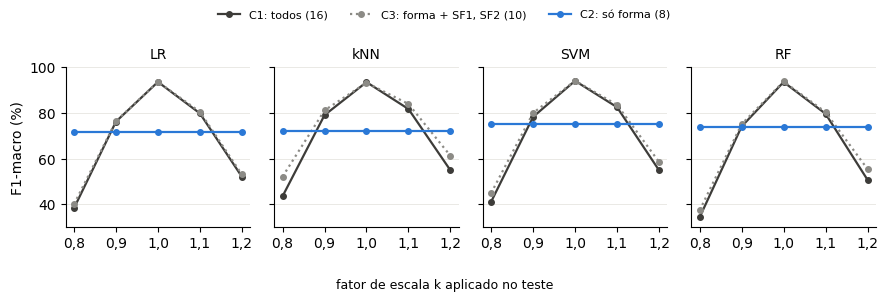

In [ ]:
base = r[r.cond != 'C4_tamanho6'][['fold', 'cond', 'model', 'f1m']].assign(k=1.0)
rb2 = pd.concat([rb, base])
piv = rb2.pivot_table(index=['model', 'cond'], columns='k', values='f1m') * 100
display(piv.round(2))

ks = [0.8, 0.9, 1.0, 1.1, 1.2]
fig, axs = plt.subplots(1, 4, figsize=(9, 2.9), sharey=True)
for ax, m in zip(axs, ORD_M):
    for c, ls in [('C1_todos16', '-'), ('C3_forma10_ingenuo', ':'), ('C2_forma8', '-')]:
        ax.plot(ks, piv.loc[(m, c), ks].values, ls, marker='o', ms=4, lw=1.6, color=COR[c], label=ROT[c])
    ax.set_title(m, fontsize=10); ax.set_xticks(ks, ['0,8', '0,9', '1,0', '1,1', '1,2'])
    ax.yaxis.grid(True, color='#e6e5e0', lw=0.6); ax.set_axisbelow(True)
axs[0].set_ylabel('F1-macro (%)'); axs[0].set_ylim(30, 100)
fig.supxlabel('fator de escala k aplicado no teste', fontsize=9)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, ncol=3, frameon=False, fontsize=8, loc='upper center')
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig('fig3_escala.png', dpi=200); plt.show()